## **Testing combinations to make interseccional groups**

In [ ]:
from itertools import combinations

In [ ]:
sensitive_features = ["age", "gender", "race"]

res = []
for i in range(1, len(sensitive_features) + 1):
    c = list(combinations(sensitive_features, i))
    print(c)
    res.extend(c)

In [ ]:
res

In [ ]:
joined = ["_".join(pairs) for pairs in res]

In [ ]:
joined

## **Test Basic Fairness Profiler**

In [ ]:
import sys
sys.path.append("../src")

In [ ]:
from fairness import FairnessProfiler
from utils import load_data

In [ ]:
df = load_data("../data/hcc_dataset.csv")

In [ ]:
df

In [ ]:
fairness_profile = FairnessProfiler(df, 
                                    sensitive_features=["gender", "diabetes"],
                                    target="class")

In [ ]:
fairness_profile.get_sensitive_features()

In [ ]:
fairness_profile.get_sensitive_groups()

In [ ]:
#Dummy pivot table: DO NOT RUN

pd.pivot_table(
    data,               # our df
    values=None,        # values to aggregate (numeric or categorical for counts)
    index=None,         # what we want in rows, usually grouping keys  
    columns=None,       # what gets passed in columns
    aggfunc='mean',     # how to summarize the data: mean, sum, count, size, min, max
    fill_value=None,    # what to put in combinations that do not exist
    margins=False,      # if true, adds total (row and colum)
    dropna=True         # drops columns in output that are all NaN
)

In [ ]:
import pandas as pd

pd.pivot_table(
    df,
    columns=["gender", "alcohol"],
    aggfunc="size"
)

In [ ]:
df.groupby(["class", "gender", "alcohol"]).size().reset_index(name="count")

In [ ]:
df.pivot_table(
    index="class", 
    columns=["gender", "alcohol", "symptoms", "ps"],
    aggfunc="size"
)

In [ ]:
import pandas as pd

In [ ]:
pivot = pd.pivot_table(
    df,
    index="class",
    columns=["gender", "alcohol", "symptoms"],
    aggfunc="size",
    fill_value=0
)

In [ ]:
pivot

In [ ]:
pivot_rate = round(pivot / pivot.values.sum() * 100, 2)

In [ ]:
pivot_rate

In [ ]:
pivot_rate.values.sum()

In [ ]:
sensitive_groups = ['gender', 'diabetes', 'gender_diabetes_bla_ble_bli']

In [ ]:
cenas = {}
for g in sensitive_groups:
    cenas[g] = g.split("_")

In [ ]:
cenas

### **Trying Target Rate by Group**

In [1]:
import sys
sys.path.append("../src")

In [2]:
from fairness import FairnessProfiler
from utils import load_data

In [3]:
df = load_data("../data/hcc_dataset.csv")

In [4]:
fairness_profile = FairnessProfiler(df, 
                                    sensitive_features=["gender", "alcohol", "endemic"],
                                    target="class")

In [5]:
fairness_profile.get_sensitive_features()

['gender', 'alcohol', 'endemic']

In [6]:
fairness_profile.get_sensitive_groups()

['gender',
 'alcohol',
 'endemic',
 'gender_alcohol',
 'gender_endemic',
 'alcohol_endemic',
 'gender_alcohol_endemic']

In [24]:
fairness_profile.target_rate_by_group_table(group="gender_alcohol_endemic")

gender  Female              Male                   
alcohol     No         Yes    No          Yes      
endemic     No   Yes    No    No   Yes     No   Yes
class                                              
Dies      4.76  0.00  0.79  5.56  0.00  25.40  1.59
Lives     5.56  1.59  4.76  6.35  1.59  38.89  3.17

In [8]:
fairness_profile.target_rate_by_group_table(group="gender", target="symptoms")

gender,Female,Male
symptoms,,
No,8.16,27.89
Yes,12.24,51.70


### **Testing without providing a target in init**

In [9]:
fp = FairnessProfiler(df, 
                      sensitive_features=["gender", "alcohol", "endemic"],
                    )

In [10]:
fp.target_rate_by_group_table(group="gender", target="alcohol")

gender,Female,Male
alcohol,,
No,12.73,13.33
Yes,6.67,67.27


In [11]:
fp.get_sensitive_features()

['gender', 'alcohol', 'endemic']

In [12]:
fp.get_sensitive_groups()

['gender',
 'alcohol',
 'endemic',
 'gender_alcohol',
 'gender_endemic',
 'alcohol_endemic',
 'gender_alcohol_endemic']

## **Trying group proportions**

In [28]:
fairness_profile.group_proportions_table("gender")

gender
Female    19.39
Male      80.61
dtype: float64

In [29]:
fairness_profile.group_proportions_table("alcohol")

alcohol
No     26.06
Yes    73.94
dtype: float64

In [30]:
fairness_profile.group_proportions_table("gender_alcohol")

alcohol,No,Yes
gender,,
Female,12.73,6.67
Male,13.33,67.27


In [31]:
fairness_profile.group_proportions_table("gender_alcohol_endemic")

alcohol     No          Yes      
endemic     No   Yes     No   Yes
gender                           
Female   10.32  1.59   5.56  0.00
Male     11.90  1.59  64.29  4.76

In [18]:
df

,gender,symptoms,alcohol,hbsag,hbeag,hbcab,hcvab,cirrhosis,endemic,smoking,...,alp,tp,creatinine,nodules,major_dim,dir_bil,iron,sat,ferritin,class
0,Male,No,Yes,No,No,No,No,Yes,No,Yes,...,150.0,7.1,0.70,1.0,3.5,0.5,NaN,NaN,NaN,Lives
1,Female,NaN,No,No,No,No,Yes,Yes,NaN,NaN,...,NaN,NaN,NaN,1.0,1.8,NaN,NaN,NaN,NaN,Lives
2,Male,No,Yes,Yes,No,Yes,No,Yes,No,Yes,...,109.0,7.0,2.10,5.0,13.0,0.1,28.0,6.0,16.0,Lives
3,Male,Yes,Yes,No,No,No,No,Yes,No,Yes,...,174.0,8.1,1.11,2.0,15.7,0.2,NaN,NaN,NaN,Dies
4,Male,Yes,Yes,Yes,No,Yes,No,Yes,No,Yes,...,109.0,6.9,1.80,1.0,9.0,NaN,59.0,15.0,22.0,Lives
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
160,Female,No,Yes,NaN,NaN,NaN,Yes,Yes,No,Yes,...,109.0,7.6,0.70,5.0,3.0,NaN,NaN,NaN,NaN,Lives
161,Female,Yes,No,NaN,NaN,NaN,NaN,Yes,No,No,...,280.0,6.7,0.70,1.0,2.2,2.3,NaN,NaN,NaN,Dies
162,Male,No,Yes,No,No,No,No,Yes,No,Yes,...,181.0,7.5,1.46,5.0,18.6,NaN,NaN,NaN,NaN,Lives
163,Male,No,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,...,170.0,8.4,0.74,5.0,18.0,NaN,NaN,NaN,NaN,Dies


In [25]:
import pandas as pd

pivot = pd.pivot_table(
    df,
    index=["gender", "alcohol", "endemic"],
    columns="class",
    aggfunc="size",
    fill_value=0
)

In [26]:
pivot

class                   Dies  Lives
gender alcohol endemic             
Female No      No          6      7
               Yes         0      2
       Yes     No          1      6
Male   No      No          7      8
               Yes         0      2
       Yes     No         32     49
               Yes         2      4

In [38]:
fairness_profile.target_rate_by_group_table("gender_alcohol_endemic")

gender  Female              Male                   
alcohol     No         Yes    No          Yes      
endemic     No   Yes    No    No   Yes     No   Yes
class                                              
Dies      4.76  0.00  0.79  5.56  0.00  25.40  1.59
Lives     5.56  1.59  4.76  6.35  1.59  38.89  3.17

In [37]:
pivot_df = fairness_profile.target_rate_by_group_table("gender_alcohol_endemic")

## **Testing internal profiler?**

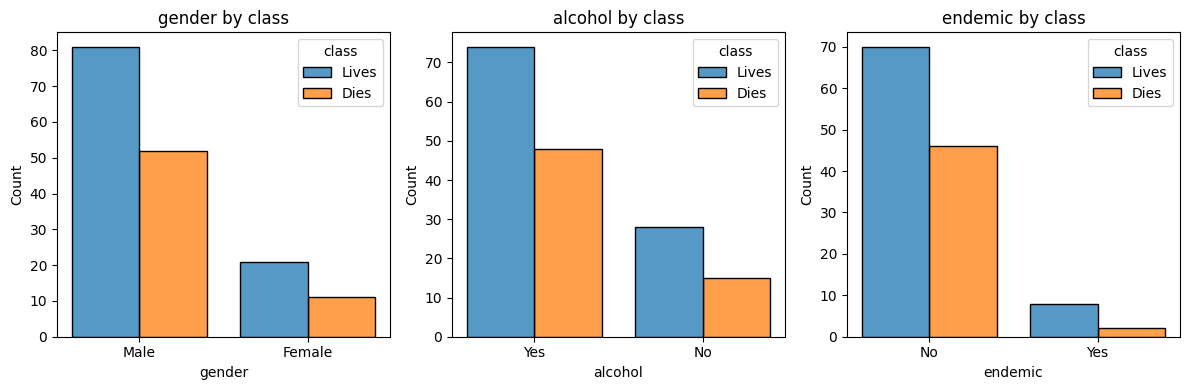

In [36]:
fairness_profile.profiler.plot_mult_histogram(cols=3, col_names=fairness_profile.get_sensitive_features(), hue="class")

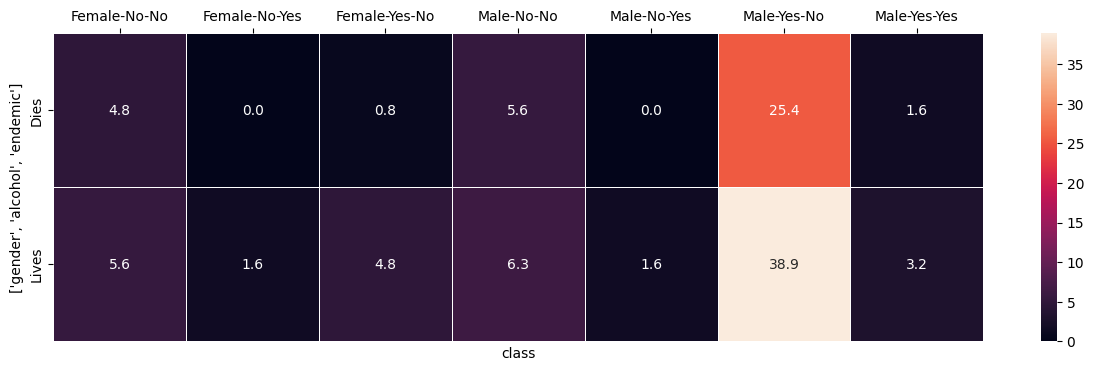

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns
index = "class"
columns = ["gender", "alcohol", "endemic"]

plt.figure(figsize=(15,4)) # needs to account for length of columns
ax = sns.heatmap(pivot_df, annot=True, fmt=".1f", linewidth=.5)
ax.set(xlabel=index, ylabel=columns)
ax.xaxis.tick_top()
plt.show()